# Homework 11: CLIP Caption Similarity and Zero-Shot Classification on CIFAR-10
Model: `openai/clip-vit-base-patch32`. Data: CIFAR-10 test set (torchvision).

In [1]:
# %pip install -q torch torchvision transformers matplotlib pandas scikit-learn

## Part 1: Caption vs. images
### Load the CLIP model

In [2]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from transformers import CLIPModel, CLIPProcessor
from torchvision.datasets import CIFAR10

device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
device

/Users/anees/.pyenv/versions/3.11.8/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1116 20:52:58.153000 90189 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 48518.66it/s]

'mps'

### Define the caption

In [3]:
caption = "a photo of a dog"

### Preprocess multiple images
100 images from each of the 10 classes, so 1000 images.

In [4]:
test = CIFAR10("data", train=False, download=True)
classes = test.classes
labels = np.array(test.targets)
idx = np.concatenate([np.where(labels == c)[0][:100] for c in range(10)])
images = [test[i][0] for i in idx]
img_labels = labels[idx]
len(images), classes

/Users/anees/.pyenv/versions/3.11.8/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


(1000,
 ['airplane',
  'automobile',
  'bird',
  'cat',
  'deer',
  'dog',
  'frog',
  'horse',
  'ship',
  'truck'])

### Extract & normalize embeddings

In [5]:
@torch.no_grad()
def image_embeddings(images, bs=256):
    out = []
    for i in range(0, len(images), bs):
        px = processor(images=images[i:i + bs], return_tensors="pt")["pixel_values"].to(device)
        f = model.get_image_features(pixel_values=px)
        out.append(getattr(f, "pooler_output", f))  # newer transformers wrap the tensor
    e = torch.cat(out)
    return e / e.norm(dim=-1, keepdim=True)

@torch.no_grad()
def text_embeddings(texts):
    tok = processor(text=texts, return_tensors="pt", padding=True).to(device)
    e = model.get_text_features(**tok)
    e = getattr(e, "pooler_output", e)
    return e / e.norm(dim=-1, keepdim=True)

img_emb = image_embeddings(images)
txt_emb = text_embeddings([caption])
img_emb.shape, txt_emb.shape

(torch.Size([1000, 512]), torch.Size([1, 512]))

### Compute similarity scores
Cosine similarity = dot product of the normalized embeddings.

In [6]:
sims = (img_emb @ txt_emb.T).squeeze(1).cpu().numpy()
class_mean = pd.Series({classes[c]: sims[img_labels == c].mean() for c in range(10)}, name="mean similarity")
class_mean.round(3)

airplane      0.203
automobile    0.201
bird          0.225
cat           0.239
deer          0.234
dog           0.259
frog          0.229
horse         0.220
ship          0.195
truck         0.195
Name: mean similarity, dtype: float32

### Visualize the results
The 8 most and 8 least similar images to the caption, with their scores, then the mean score per class.

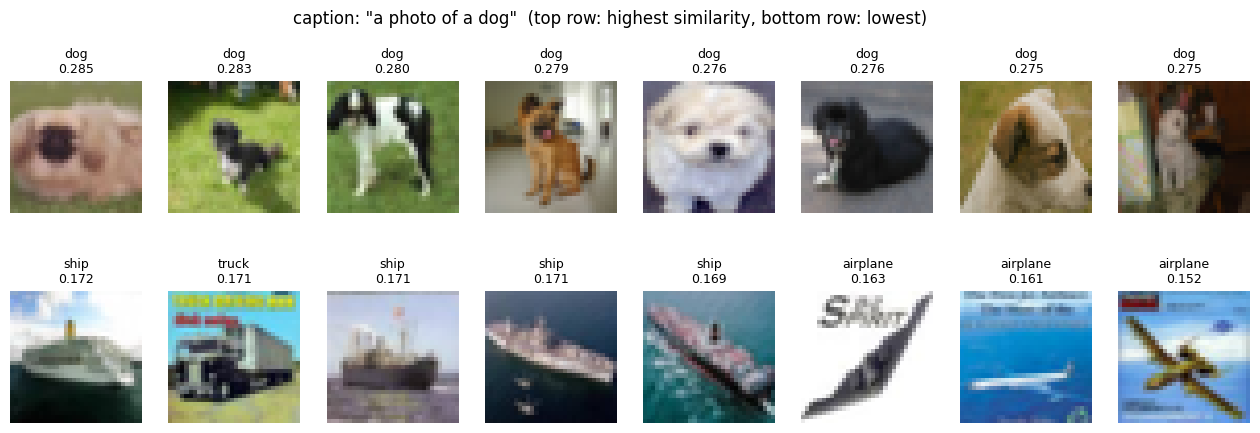

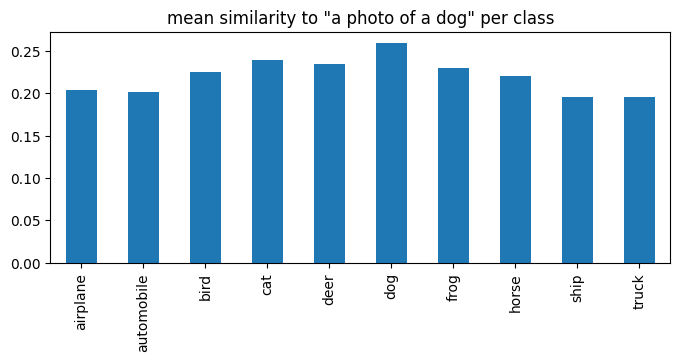

In [7]:
order = np.argsort(-sims)
fig, ax = plt.subplots(2, 8, figsize=(16, 5))
for j, i in enumerate(list(order[:8]) + list(order[-8:])):
    a = ax[j // 8, j % 8]
    a.imshow(images[i]); a.axis("off")
    a.set_title(f"{classes[img_labels[i]]}\n{sims[i]:.3f}", fontsize=9)
fig.suptitle(f'caption: "{caption}"  (top row: highest similarity, bottom row: lowest)')
plt.show()

class_mean.plot.bar(figsize=(8, 3), title=f'mean similarity to "{caption}" per class'); plt.show()

### Findings
* Caption: `"a photo of a dog"`, compared against 1000 CIFAR-10 test images (100 per class).
* All 8 highest scoring images are dogs (scores 0.275 to 0.285). The 8 lowest are ships, airplanes and a truck (0.152 to 0.172), so the ranking matches the caption even though the images are only 32x32.
* Mean similarity per class: dog 0.259 is highest, then cat 0.239 and deer 0.234 (other animals). Ship and truck are lowest at 0.195. CLIP places semantically related classes (animals) closer to the caption than unrelated ones (vehicles).
* The absolute scores are small (about 0.15 to 0.29) and the range is narrow. This is normal for CLIP cosine similarity. What matters is the relative order, not the raw value.

## Part 2: Zero-shot classification on CIFAR-10
One text prompt per class, `"a photo of a {class}"`. Each test image is assigned to the class whose prompt embedding is most similar. Uses the full 10,000 image test set.

In [8]:
prompts = [f"a photo of a {c}" for c in classes]
prompt_emb = text_embeddings(prompts)
all_emb = image_embeddings([img for img, _ in test])
pred = (all_emb @ prompt_emb.T).argmax(1).cpu().numpy()
print("overall accuracy:", round((pred == labels).mean(), 4))

overall accuracy: 0.888


### Per-class accuracy

In [9]:
per_class = pd.Series({classes[c]: (pred[labels == c] == c).mean() for c in range(10)}, name="accuracy")
per_class.round(3)

airplane      0.901
automobile    0.976
bird          0.888
cat           0.860
deer          0.765
dog           0.884
frog          0.774
horse         0.976
ship          0.955
truck         0.901
Name: accuracy, dtype: float64

### Confusion matrix

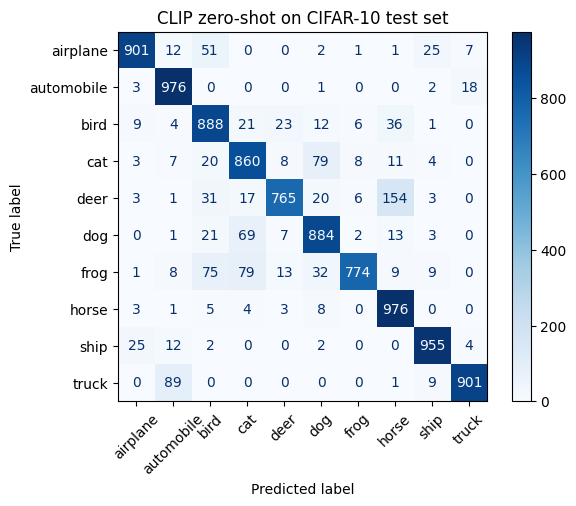

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(labels, pred, display_labels=classes, xticks_rotation=45, cmap="Blues")
plt.title("CLIP zero-shot on CIFAR-10 test set"); plt.show()

### Findings
* Overall zero-shot accuracy on the 10,000 test images is 88.8% with no training on CIFAR-10, only the prompt `"a photo of a {class}"`.
* Best classes: automobile 97.6%, horse 97.6%, ship 95.5%. Worst: deer 76.5%, frog 77.4%, cat 86.0%.
* Main confusions from the matrix: deer -> horse (154 images), truck -> automobile (89), cat -> dog (79), frog -> cat (79), frog -> bird (75), dog -> cat (69). The errors are between visually similar classes, not random.
* The low resolution of CIFAR-10 (32x32, upsampled to 224x224 for CLIP) makes fine distinctions like deer vs. horse and cat vs. dog harder. Better prompts (for example "a blurry photo of a {class}") or averaging several prompts per class could raise accuracy.